# 02 - Data Preprocessing
**Project:** Customer Churn Prediction and Recommendation  
**Goal:** Clean data, encode target & features, scale numerical columns, and prepare train/test split.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader   import load_dataset, identify_features
from src.preprocessor  import clean_data, encode_target, encode_features, scale_features, split_data

DATA_PATH = '../data/indian_netflix_churn_dataset_v2.csv'

## 2.1 Load Raw Data

In [2]:
df = load_dataset("E:\MCA\SEM 3\Project\Customer_churn_prediction\customer_churn_project\data\indian_netflix_churn_dataset_v2.csv")
print('Raw shape:', df.shape)
df.head(3)

Loaded: 10,000 rows x 22 columns
Raw shape: (10000, 22)


,Customer_ID,Customer_Name,Gender,Age,State,City,Occupation,Monthly_Income,Subscription_Plan,Monthly_Fee,...,Favorite_Genre,Device_Type,Payment_Method,Customer_Satisfaction,Support_Tickets,Buffering_Complaints,Concurrent_Screens,Recommendation_Clicks,Churn,Churn_Type
0,100001,Turvi Comar,Male,40,Karnataka,Mysore,Government Employee,57333,Mobile,149,...,Crime,Tablet,Debit Card,3,3,9,2,16,0,Active Customer
1,100002,Nathan Pingle,Female,43,Uttar Pradesh,Kanpur,Student,265786,Basic,199,...,Documentary,Smart TV,PhonePe,5,3,1,3,43,0,Active Customer
2,100003,Irya Dara,Male,28,Rajasthan,Jodhpur,Government Employee,20185,Premium,649,...,Romance,Laptop,Paytm,2,0,0,4,17,0,Active Customer


## 2.2 Handle Missing Values & Duplicates

In [3]:
print('Missing before cleaning:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('Duplicates:', df.duplicated().sum())

Missing before cleaning:
Series([], dtype: int64)
Duplicates: 0


In [4]:
df = clean_data(df)
print('Shape after cleaning:', df.shape)

Removed 0 duplicates
Missing after cleaning: 0
Shape after cleaning: (10000, 22)


## 2.3 Encode Target Variable (Churn)

In [5]:
df = encode_target(df)
print('Churn value counts:')
print(df['Churn'].value_counts())

Target — Active(0): 6,858 | Churned(1): 3,142
Churn value counts:
Churn
0    6858
1    3142
Name: count, dtype: int64


## 2.4 Identify Features

In [6]:
features = identify_features(df)
num_cols = features['numerical']
cat_cols = features['categorical']
print('Numerical  :', num_cols)
print('Categorical:', cat_cols)

Numerical  (10): ['Age', 'Monthly_Income', 'Monthly_Fee', 'Tenure_Months', 'Watch_Hours_Per_Month', 'Customer_Satisfaction', 'Support_Tickets', 'Buffering_Complaints', 'Concurrent_Screens', 'Recommendation_Clicks']
Categorical(8): ['Gender', 'State', 'City', 'Occupation', 'Subscription_Plan', 'Favorite_Genre', 'Device_Type', 'Payment_Method']
Numerical  : ['Age', 'Monthly_Income', 'Monthly_Fee', 'Tenure_Months', 'Watch_Hours_Per_Month', 'Customer_Satisfaction', 'Support_Tickets', 'Buffering_Complaints', 'Concurrent_Screens', 'Recommendation_Clicks']
Categorical: ['Gender', 'State', 'City', 'Occupation', 'Subscription_Plan', 'Favorite_Genre', 'Device_Type', 'Payment_Method']


## 2.5 Encode Categorical Features

In [7]:
print('Sample categorical values before encoding:')
for col in cat_cols[:3]:
    print(f'  {col}: {df[col].unique()[:5]}')

Sample categorical values before encoding:
  Gender: ['Male' 'Female']
  State: ['Karnataka' 'Uttar Pradesh' 'Rajasthan' 'Gujarat' 'Maharashtra']
  City: ['Mysore' 'Kanpur' 'Jodhpur' 'Vadodara' 'Pune']


In [8]:
df = encode_features(df, cat_cols, save_dir='../models')
print('After encoding:')
df[cat_cols[:3]].head()

Encoded 8 categorical columns
After encoding:


,Gender,State,City
0,1,2,18
1,0,8,12
2,1,6,11
3,1,1,27
4,1,4,23


## 2.6 Scale Numerical Features

In [9]:
print('Numerical stats before scaling:')
print(df[num_cols].describe().round(2))

Numerical stats before scaling:
            Age  Monthly_Income  Monthly_Fee  Tenure_Months  \
count  10000.00        10000.00     10000.00       10000.00   
mean      38.92       157520.09       373.54          30.46   
std       12.45        82032.58       207.67          17.27   
min       18.00        15015.00       149.00           1.00   
25%       28.00        87121.50       199.00          15.00   
50%       39.00       157865.50       199.00          30.00   
75%       50.00       228878.00       649.00          46.00   
max       60.00       299991.00       649.00          60.00   

       Watch_Hours_Per_Month  Customer_Satisfaction  Support_Tickets  \
count               10000.00               10000.00         10000.00   
mean                   52.73                   3.03             4.96   
std                    27.81                   1.42             3.14   
min                     5.00                   1.00             0.00   
25%                    29.00            

In [10]:
df = scale_features(df, num_cols, save_dir='../models')
print('Numerical stats after scaling (mean~0, std~1):')
print(df[num_cols].describe().round(2))

Scaled 10 numerical columns
Numerical stats after scaling (mean~0, std~1):
            Age  Monthly_Income  Monthly_Fee  Tenure_Months  \
count  10000.00        10000.00     10000.00       10000.00   
mean       0.00           -0.00        -0.00          -0.00   
std        1.00            1.00         1.00           1.00   
min       -1.68           -1.74        -1.08          -1.71   
25%       -0.88           -0.86        -0.84          -0.90   
50%        0.01            0.00        -0.84          -0.03   
75%        0.89            0.87         1.33           0.90   
max        1.69            1.74         1.33           1.71   

       Watch_Hours_Per_Month  Customer_Satisfaction  Support_Tickets  \
count               10000.00               10000.00         10000.00   
mean                   -0.00                  -0.00            -0.00   
std                     1.00                   1.00             1.00   
min                    -1.72                  -1.44            -1.58 

## 2.7 Train / Test Split

In [11]:
all_features = num_cols + cat_cols
X_train, X_test, y_train, y_test = split_data(df, all_features)

print(f'X_train: {X_train.shape} | X_test: {X_test.shape}')
print(f'y_train churn rate: {y_train.mean()*100:.2f}%')
print(f'y_test  churn rate: {y_test.mean()*100:.2f}%')

Train: 8,000 | Test: 2,000
X_train: (8000, 18) | X_test: (2000, 18)
y_train churn rate: 31.42%
y_test  churn rate: 31.40%


## 2.8 Class Balance Check

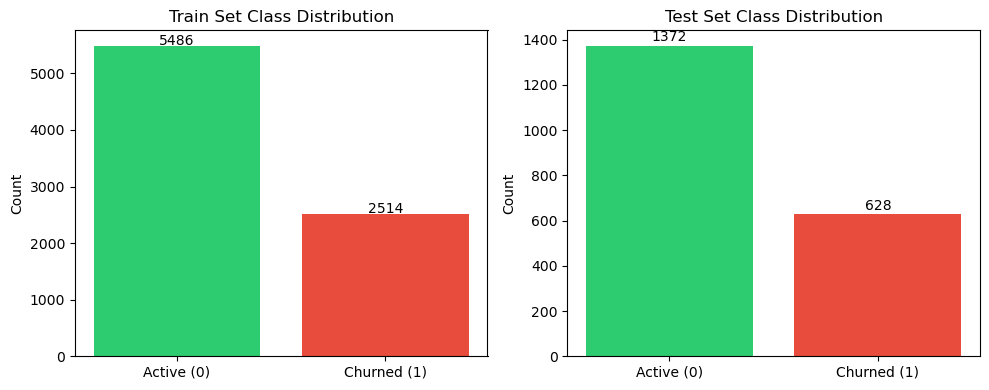

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, split, label in zip(axes, [y_train, y_test], ['Train', 'Test']):
    counts = split.value_counts()
    ax.bar(['Active (0)', 'Churned (1)'], counts.values,
           color=['#2ecc71', '#e74c3c'])
    ax.set_title(f'{label} Set Class Distribution')
    ax.set_ylabel('Count')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 20, str(v), ha='center')
plt.tight_layout()
plt.savefig('../outputs/class_balance.png', dpi=150)
plt.show()

## Summary
- Data cleaned: duplicates removed, missing values filled.
- Target encoded: `Churn` → 0 (Active) / 1 (Churned).
- Categorical features label-encoded; encoders saved.
- Numerical features standard-scaled; scaler saved.
- Train/test split (80/20) with stratification applied.
- **Next step:** Notebook 03 — Exploratory Data Analysis